# 08 · EDA multivariado

**Fase CRISP-DM:** 2. Entendimiento de los datos

**Objetivo:** mirar **muchas variables a la vez**, cosa que el bivariado (notebook 07) no puede hacer. Hay tres preguntas:

1. **Correlaciones en bloque:** ¿qué features del comensal dicen lo mismo? Meter dos veces la misma información infla el modelo sin aportar.
2. **MCA** (análisis de correspondencias múltiples): ¿cómo se organizan juntas las variables **categóricas** de la mesa (franja, día, cocina, tamaño, nivel de precio, tamaño del restaurante)? Es el equivalente categórico del PCA.
3. **Clustering de comensales:** ¿el comportamiento forma **segmentos**? ¿Esos segmentos recuperan los **gustos latentes** de la simulación?

**Regla de la verdad oculta:** el análisis usa solo lo observable, como lo vería Puzzle. Los gustos latentes (`ground_truth/`) se usan **solo para verificar**, igual que en el notebook 05.

**Entradas:** tablas del contrato y, para verificar, `ground_truth/`. **Salidas:** figuras `reports/figures/08_*.png` y decisiones para la ingeniería de features (notebooks 09 y 10).

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración

La unidad de análisis de las secciones 1 y 3 es el **comensal registrado**. Cada uno se describe con 30 números de comportamiento observado (`diner_behavior_matrix`):

- **Cocinas (20):** qué proporción de sus visitas fue a cada cocina.
- **Hábitos (5):** líneas propias e individuales por visita de cada tipo de plato (¿pide entrada? ¿postre?).
- **Gusto y gasto:** picante medio pedido y log del ticket por persona mediano.
- **Compartir:** proporción de sus mesas con algo compartido.
- **Variedad:** restaurantes distintos / visitas. Se usa en lugar de las dos variables por separado, que tenían ρ = 0.84 en el notebook 07.
- **Frecuencia:** log de las visitas.

Se descartan los comensales con menos de 5 visitas, porque con 2 o 3 visitas las proporciones son ruido.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from puzzle_recsys.config import load_paths, load_simulation
from puzzle_recsys.eda.frames import session_frame
from puzzle_recsys.eda.multivariate import (
    cluster_diners,
    diner_behavior_matrix,
    guest_trait,
    kmeans_scan,
    latent_diner_traits,
    mca_summary,
    recovery_vs_truth,
    redundant_pairs,
    sharing_by_table_trait,
    table_categories,
    trait_recovery,
)
from puzzle_recsys.eda.plots import plot_corr_matrix, plot_mca_map
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for

paths, sim = load_paths(), load_simulation()
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
t = {n: repo.read_table(n) for n in ["restaurants", "menu_items", "dining_sessions", "guests", "order_items"]}
figs = paths.figures
figs.mkdir(parents=True, exist_ok=True)
SEED = sim.seed

mesas = session_frame(t["dining_sessions"], t["order_items"], t["restaurants"], t["menu_items"], sim.calendar["timezone"])
X = diner_behavior_matrix(mesas, t["guests"], t["order_items"], t["menu_items"], min_visits=5)
pd.Series({"mesas": len(mesas), "comensales con 5+ visitas": len(X), "features por comensal": X.shape[1],
           "faltantes": int(X.isna().sum().sum())}, name="valor").to_frame().T

,mesas,comensales con 5+ visitas,features por comensal,faltantes
valor,512907,20136,30,0


## 1. Correlaciones

Se calcula la matriz de **Spearman** entre las 30 features del comensal (rangos, porque ninguna es normal). El objetivo es encontrar **bloques redundantes**: pares con |ρ| ≥ 0.5 dicen casi lo mismo, y en el modelo conviene usar uno solo o combinarlos.

,a,b,rho
0,variedad,log_visitas,-0.806
1,cocina__mexicana,cocina__tacos_tortas,-0.583


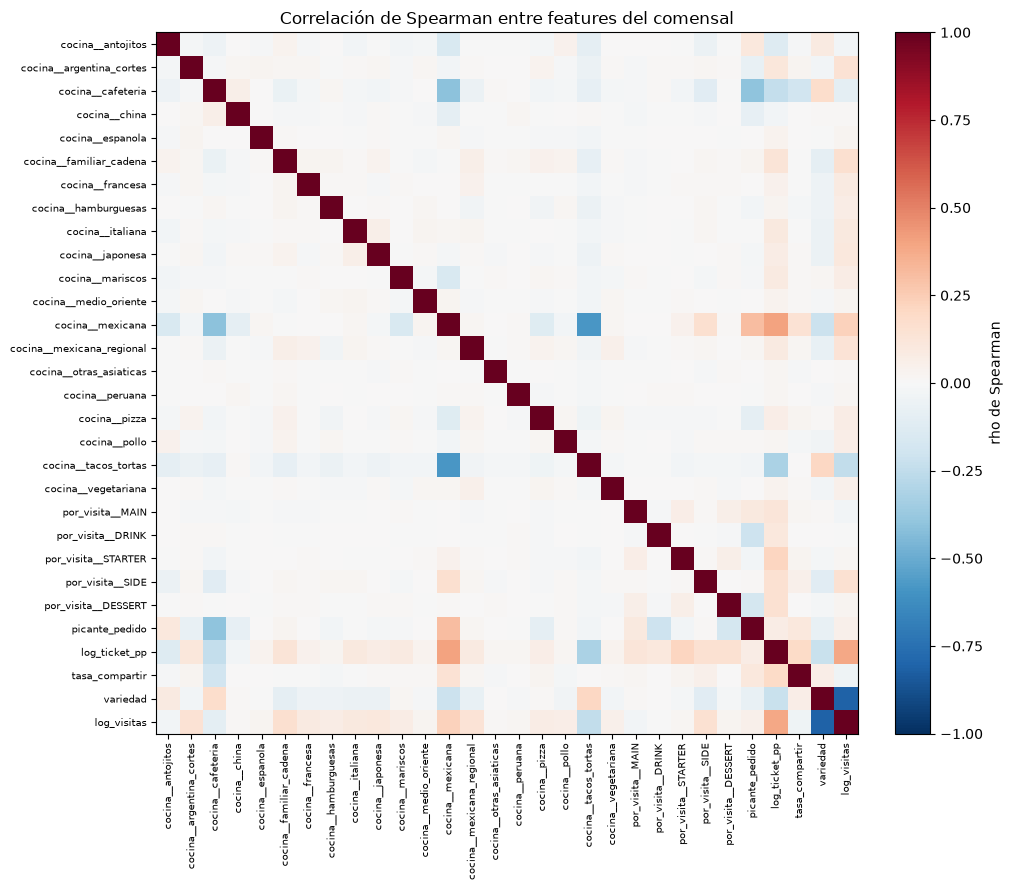

In [2]:
corr = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
plot_corr_matrix(corr, title="Correlación de Spearman entre features del comensal", ax=ax)
fig.tight_layout()
fig.savefig(figs / "08_correlaciones.png", dpi=150)
redundant_pairs(corr, threshold=0.5).round(3)

In [3]:
# Pares moderados (0.3 ≤ |ρ| < 0.5): relación real, pero cada uno aporta algo propio.
moderados = redundant_pairs(corr, threshold=0.3)
moderados[moderados["rho"].abs() < 0.5].round(3)

,a,b,rho
2,cocina__cafeteria,cocina__mexicana,-0.407
3,cocina__cafeteria,picante_pedido,-0.406
4,cocina__mexicana,log_ticket_pp,0.399
5,log_ticket_pp,log_visitas,0.384
6,cocina__tacos_tortas,log_ticket_pp,-0.320
7,cocina__mexicana,picante_pedido,0.311


**Lectura:**

- **Variedad ↔ frecuencia:** quien sale mucho repite restaurantes, porque la lealtad crece con las visitas. Es la misma redundancia del notebook 07 (visitas ↔ restaurantes distintos), ahora como cociente.
- **Mexicana ↔ tacos y tortas:** las proporciones por cocina suman 1, así que si una sube, otra baja (datos **composicionales**). Esta correlación negativa es **mecánica**: no dice que a quien le gusta la mexicana le disgusten los tacos.
- Los **hábitos** por tipo de plato casi no se correlacionan entre sí: pedir entrada no predice pedir postre. Cada hábito es información propia.

## 2. MCA: estructura de las mesas

El MCA hace con variables categóricas lo que el PCA hace con numéricas: busca las pocas **dimensiones** que resumen cómo se combinan las categorías. Dos categorías cercanas en el mapa aparecen **juntas en las mismas mesas**.

- **Variables:** franja, fin de semana, cocina (las 8 más comunes, el resto en "otras"), personas (1 / 2 / 3-4 / 5+), nivel de precio (cuartiles) y tamaño del restaurante (personal).
- **Muestra:** 50,000 mesas al azar. Sobra para estimar las coordenadas y el ajuste tarda segundos.
- **Corrección de Benzécri:** el porcentaje de inercia "crudo" del MCA subestima mucho las primeras dimensiones, porque la codificación one-hot fabrica inercia artificial. La corrección se queda solo con las dimensiones mayores que el promedio y las reescala.

In [4]:
cats = table_categories(mesas, top_cuisines=8)
muestra = cats.sample(50_000, random_state=SEED)
mca = mca_summary(muestra, n_components=6, seed=SEED)
mca["inercia"].round(3)

,dimension,eigenvalor,pct_crudo,pct_benzecri
0,1,0.278,7.572,56.827
1,2,0.231,6.294,18.963
2,3,0.222,6.055,14.133
3,4,0.200,5.468,5.278
4,5,0.195,5.315,3.672
5,6,0.182,4.972,1.128


,variable,categoria,dim1,dim2,contribucion_1_2
0,nivel_precio,Q4,1.150,0.747,0.289
1,cocina,antojitos,-1.763,2.164,0.279
2,nivel_precio,Q1,-0.988,0.580,0.236
3,nivel_precio,Q3,0.256,-0.872,0.140
4,cocina,mariscos,1.370,1.810,0.132
5,cocina,mexicana,0.487,-0.404,0.125
6,cocina,familiar_cadena,3.389,2.687,0.122
7,personal,251 y más personas,-1.104,5.063,0.108
8,cocina,cafeteria,-0.937,-0.295,0.088
9,personal,51 a 100 personas,1.942,1.597,0.080


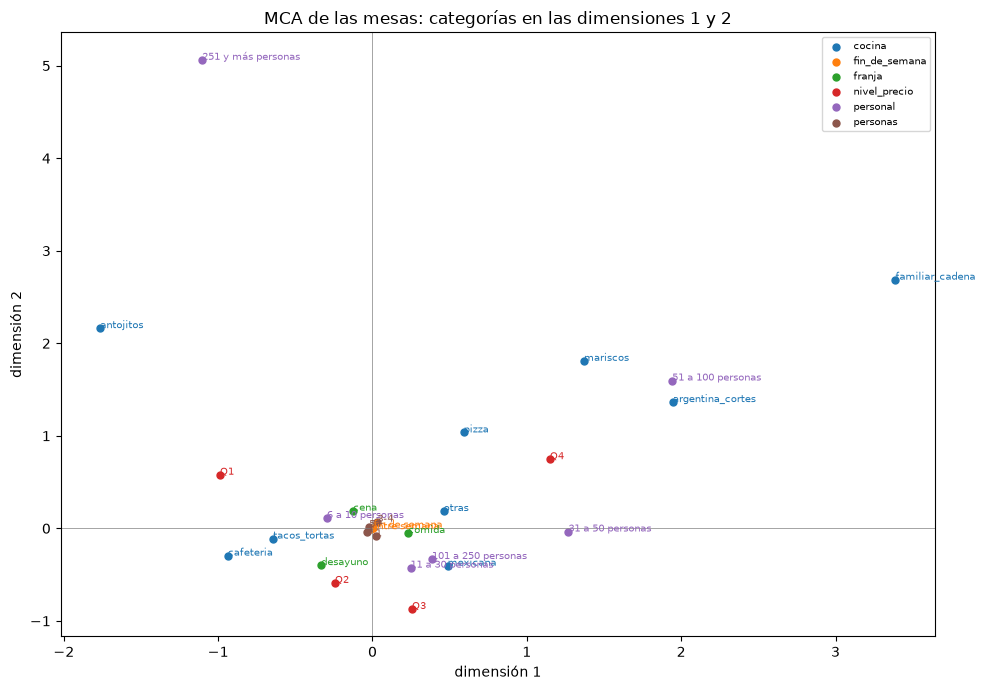

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))
plot_mca_map(mca["categorias"], title="MCA de las mesas: categorías en las dimensiones 1 y 2", ax=ax)
fig.tight_layout()
fig.savefig(figs / "08_mca.png", dpi=150)
mca["categorias"].sort_values("contribucion_1_2", ascending=False).head(12)[
    ["variable", "categoria", "dim1", "dim2", "contribucion_1_2"]].round(3).reset_index(drop=True)

In [6]:
# Contribución de cada VARIABLE (suma de sus categorías) a las dos primeras dimensiones.
mca["categorias"].groupby("variable")["contribucion_1_2"].sum().sort_values(ascending=False).round(3)

variable
cocina           0.874
nivel_precio     0.733
personal         0.334
franja           0.056
personas         0.003
fin_de_semana    0.000
Name: contribucion_1_2, dtype: float64

## 3. Clustering de comensales vs. segmentos simulados

**Procedimiento:**

1. **Estandarizar** las 30 features, porque K-means usa distancias y una feature con mayor escala dominaría.
2. **PCA** quedándose con el 90 % de la varianza, para quitar ruido y la redundancia de la sección 1.
3. **K-means** para k = 2 a 10. Se elige k con la **silueta**, que va de -1 a 1: cerca de 0 quiere decir que los grupos se enciman y que no hay estructura de grupos.
4. **Verificar contra la verdad oculta:** ¿los grupos separan los gustos latentes? Se usa ε² para los rasgos numéricos y la información mutua ajustada (AMI) para la cocina dominante.

(       componentes PCA (90 %)
 valor                      24,
     k     inercia  silueta
 0   2  515910.391    0.099
 1   3  499603.684    0.073
 2   4  482294.113    0.075
 3   5  468447.451    0.075
 4   6  458198.943    0.081
 5   7  443684.581    0.074
 6   8  433047.939    0.069
 7   9  422486.146    0.064
 8  10  407815.796    0.060)

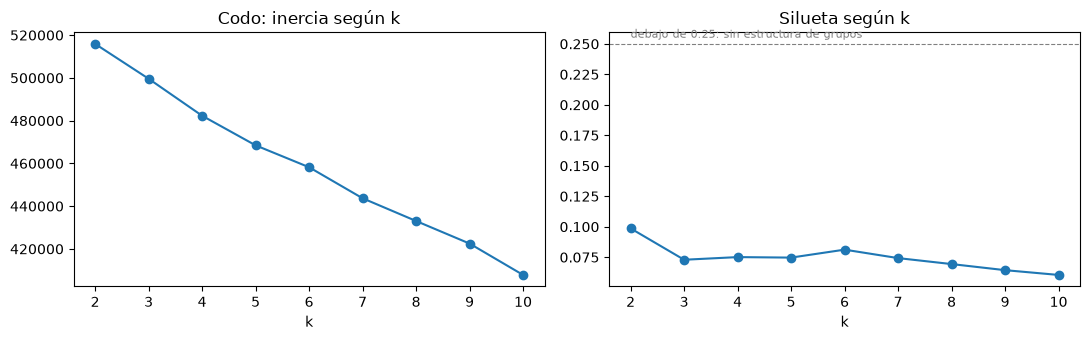

In [7]:
z = StandardScaler().fit_transform(X.to_numpy())
emb = PCA(n_components=0.9, svd_solver="full", random_state=SEED).fit_transform(z)
scan = kmeans_scan(emb, ks=range(2, 11), seed=SEED, silhouette_sample=5_000)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(scan["k"], scan["inercia"], marker="o"); axes[0].set_title("Codo: inercia según k"); axes[0].set_xlabel("k")
axes[1].plot(scan["k"], scan["silueta"], marker="o"); axes[1].set_title("Silueta según k"); axes[1].set_xlabel("k")
axes[1].axhline(0.25, color="grey", linestyle="--", linewidth=0.8)
axes[1].annotate("debajo de 0.25: sin estructura de grupos", (2, 0.255), fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(figs / "08_eleccion_k.png", dpi=150)
pd.Series({"componentes PCA (90 %)": emb.shape[1]}).to_frame("valor").T, scan.round(3)

La silueta queda **muy por debajo de 0.25 para todo k** y la inercia baja sin un codo claro. Los comensales **no forman grupos naturales**. Aun así se ajusta un K-means (con el k de mejor silueta) para ver qué recupera.

In [8]:
k_best = int(scan.loc[scan["silueta"].idxmax(), "k"])
clusters = cluster_diners(X, k=k_best, seed=SEED, variance=0.9)
cuisines = sorted(t["restaurants"]["cuisine_pred"].unique())
gt = repo.ground_truth
latent = latent_diner_traits(gt.read_table("diner_tastes"), gt.read_table("duplicate_accounts"), X.index, cuisines)
habits = ["habit_starter", "habit_drink", "habit_dessert", "habit_side"]
numeric = latent[["spice_tolerance", "price_sensitivity", "distance_sensitivity", "variety_seeking", "sharer", *habits]]
display(clusters.labels.value_counts().rename("comensales").to_frame().T)
recovery_vs_truth(clusters.labels, numeric, {"cocina_dominante": latent["cocina_dominante"]}).round(3)

cluster,1,0
comensales,10926,9210


,rasgo,metrica,valor,efecto
0,spice_tolerance,epsilon2,0.002,despreciable
1,price_sensitivity,epsilon2,0.001,despreciable
2,distance_sensitivity,epsilon2,0.000,despreciable
3,variety_seeking,epsilon2,0.000,despreciable
4,sharer,epsilon2,0.003,despreciable
5,habit_starter,epsilon2,0.005,despreciable
6,habit_drink,epsilon2,0.000,despreciable
7,habit_dessert,epsilon2,0.000,despreciable
8,habit_side,epsilon2,0.001,despreciable
9,cocina_dominante,AMI,0.026,despreciable


Los grupos **no recuperan casi ningún rasgo latente**. ¿Quiere decir que el comportamiento no tiene la señal? **No.** Hay que revisarlo comensal por comensal: cada feature observada contra el rasgo latente que debería reflejar.

In [9]:
latent["cocina_dominante_obs"] = X.filter(like="cocina__").idxmax(axis=1).str.removeprefix("cocina__")
pairs = [
    ("por_visita__STARTER", "habit_starter"),
    ("por_visita__DRINK", "habit_drink"),
    ("por_visita__DESSERT", "habit_dessert"),
    ("por_visita__SIDE", "habit_side"),
    ("picante_pedido", "spice_tolerance"),
    ("tasa_compartir", "sharer"),
    ("log_ticket_pp", "price_sensitivity"),
    ("variedad", "variety_seeking"),
]
display(trait_recovery(X, latent, pairs).round(3))
acierto = (latent["cocina_dominante_obs"] == latent["cocina_dominante"]).mean()
pd.Series({"cocina más visitada = cocina de mayor afinidad latente": f"{acierto:.1%}",
           "azar (1 / 20 cocinas)": "5.0%"}).to_frame("valor")

,observado,latente,rho,efecto
0,por_visita__STARTER,habit_starter,0.865,fuerte
1,por_visita__DRINK,habit_drink,0.863,fuerte
2,por_visita__DESSERT,habit_dessert,0.810,fuerte
3,por_visita__SIDE,habit_side,0.680,fuerte
4,picante_pedido,spice_tolerance,0.404,moderado
5,tasa_compartir,sharer,0.460,moderado
6,log_ticket_pp,price_sensitivity,0.096,despreciable
7,variedad,variety_seeking,0.043,despreciable


,valor
cocina más visitada = cocina de mayor afinidad latente,50.8%
azar (1 / 20 cocinas),5.0%


**La señal está, pero es continua, no por grupos.** En la simulación los gustos son **continuos e independientes entre sí** (S4): se puede tener mucho hábito de postre y poco de entrada, en cualquier combinación. Entonces no existen "tipos de comensal" que un clustering pueda encontrar, y un K-means solo corta una nube continua en pedazos arbitrarios.

### Verificación de la corrección 8: compartir según quién se sienta

Con la verdad oculta se calcula el gusto medio por compartir de **todas** las personas sentadas en cada mesa, registradas y anónimas. Después se compara qué proporción de mesas comparte en cada tercil de ese gusto. Solo cuentan las mesas de 2 o más personas.

In [10]:
traits = guest_trait(t["guests"], gt.read_table("guest_tastes"),
                     [gt.read_table("diner_tastes"), gt.read_table("anonymous_tastes")], "sharer")
sharing_by_table_trait(t["dining_sessions"], traits, t["order_items"], q=3).round(3)

,cuantil,mesas,gusto_medio,pct_comparten
0,1,142029,0.116,14.977
1,2,142028,0.194,27.768
2,3,142029,0.293,37.720


## 4. Hallazgos

Resumen de las decisiones que pasan a la ingeniería de features:

In [11]:
pd.DataFrame([
    {"hallazgo": "variedad ↔ frecuencia redundantes", "decisión": "usar el cociente (variedad) y log de visitas, no los conteos"},
    {"hallazgo": "cocinas composicionales", "decisión": "afinidad por cocina como proporción con suavizado; no interpretar sus correlaciones"},
    {"hallazgo": "hábitos independientes y con señal fuerte", "decisión": "una feature de hábito por tipo de plato"},
    {"hallazgo": "sin segmentos naturales", "decisión": "no usar el clúster como feature; usar el perfil continuo"},
    {"hallazgo": "MCA: precio, cocina y tamaño del restaurante van juntos", "decisión": "features de restaurante (nivel de precio, cocina) además de las del comensal"},
    {"hallazgo": "compartir ahora depende de quién se sienta (corrección 8)", "decisión": "tasa de compartir del comensal y de la mesa como features de \"para la mesa\""},
    {"hallazgo": "sensibilidad al precio y variedad casi no se ven", "decisión": "documentarlas como señales débiles en la ficha del modelo"},
]).style.hide(axis="index")

hallazgo,decisión
variedad ↔ frecuencia redundantes,"usar el cociente (variedad) y log de visitas, no los conteos"
cocinas composicionales,afinidad por cocina como proporción con suavizado; no interpretar sus correlaciones
hábitos independientes y con señal fuerte,una feature de hábito por tipo de plato
sin segmentos naturales,no usar el clúster como feature; usar el perfil continuo
"MCA: precio, cocina y tamaño del restaurante van juntos","features de restaurante (nivel de precio, cocina) además de las del comensal"
compartir ahora depende de quién se sienta (corrección 8),"tasa de compartir del comensal y de la mesa como features de ""para la mesa"""
sensibilidad al precio y variedad casi no se ven,documentarlas como señales débiles en la ficha del modelo


## Conclusiones

### 1. Lo que este EDA destapó: compartir no dependía de quién se sentaba

La primera corrida mostró que la tasa de compartir de cada comensal **no tenía relación** con su gusto latente por compartir (ρ = -0.008). En el simulador, el rasgo `sharer` solo decidía **quién** pedía el plato al centro, no **si** la mesa compartía, que dependía solo del número de personas. Como la lista "para la mesa" depende justo de eso, se corrigió (supuesto S17; notebook 03, corrección 8) y se volvió a ejecutar toda la cadena. Ahora:

| Gusto medio de la mesa por compartir (tercil) | Bajo | Medio | Alto |
|---|---|---|---|
| Mesas de 2+ personas que comparten algo | 15 % | 28 % | 38 % |

- Tasa de compartir observada ↔ rasgo latente: ρ = **0.46** (antes -0.008).
- La tasa global de mesas que comparten **no cambió** (0.225 contra 0.224 en el notebook 04), porque la corrección se normalizó para que una mesa promedio conserve la tasa de siempre.

### 2. Correlaciones: dos redundancias, una de ellas mecánica

- **Variedad ↔ frecuencia** (ρ = -0.81): quien sale mucho repite restaurantes. Se usan las dos, pero sabiendo que comparten información.
- **Mexicana ↔ tacos y tortas** (ρ = -0.58): es **mecánica**, porque las proporciones por cocina suman 1. No hay que leerla como "a quien le gusta una le disgusta la otra".
- Moderadas con explicación: cafetería ↔ picante (ρ = -0.41, la cafetería casi no tiene picante) y ticket ↔ frecuencia (ρ = 0.38, quien gasta más sale más seguido y gasta algo más por visita; notebook 03, corrección 2).
- Los **hábitos** por tipo de plato son casi independientes entre sí: cada uno aporta información propia.

### 3. MCA: las mesas se organizan por el restaurante, no por el momento

- Con la corrección de Benzécri, las dos primeras dimensiones resumen el **76 %** de la inercia (57 % + 19 %). El porcentaje crudo (7.6 % + 6.3 %) subestima mucho, como era de esperar con one-hot.
- Las dimensiones 1 y 2 las arman **la cocina** (contribución 0.87), **el nivel de precio** (0.73) y **el tamaño del restaurante** (0.33). La franja (0.06), el tamaño de mesa (0.003) y el fin de semana (0.000) casi no pesan.
- **Lectura:** el eje principal va de antojitos y precios bajos (Q1) a mariscos, cadenas familiares y precios altos (Q4). La franja sí cambia la cocina (V = 0.19, notebook 07), pero es una variación **dentro** de esa estructura, no un eje propio.

### 4. Clustering: no hay segmentos, y está bien

- La **silueta no pasa de 0.10** para ningún k entre 2 y 10, muy por debajo de 0.25. No hay grupos naturales.
- Los 2 grupos de K-means **no recuperan ningún rasgo latente** (todos los ε² < 0.01; AMI con la cocina dominante = 0.03).
- **Pero la señal está, comensal por comensal:** los hábitos de entrada, bebida y postre tienen ρ de 0.81 a 0.87 con el rasgo latente, la guarnición 0.68, el picante 0.40 y compartir 0.46. La cocina más visitada coincide con la de mayor afinidad latente en el **51 %** de los casos (el azar sería 5 %).
- **Por qué:** en la simulación los gustos son **continuos e independientes** (S4). No hay "tipos de comensal" que encontrar: un K-means solo corta una nube continua en pedazos arbitrarios. Con datos reales de Puzzle podría haber segmentos (los gustos reales suelen estar correlacionados); este análisis se repite entonces.
- **Señales débiles** (pasan a la ficha del modelo): la sensibilidad al precio casi no se ve en el ticket (ρ = 0.10), porque el ticket lo define el presupuesto; y el gusto por la variedad casi no se ve en los restaurantes distintos (ρ = 0.04), porque domina la lealtad.

**Decisión para los notebooks 09 y 10:** el comensal se representa con su **perfil continuo** (afinidad por cocina, hábitos por tipo de plato, picante, ticket, tasa de compartir), no con una etiqueta de clúster.

**Pasa al notebook 09:** homologación de platillos y perfil del comensal calculado punto en el tiempo.
